In [1]:
import time
import warnings

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.stats import norm

from model import Model
from data_processing import DataProcessor
from slim_config import SlimConfig

warnings.filterwarnings("ignore", category=FutureWarning)

# ---- settings -------------------------------------------------------------
K, LAM, ALPHA = 20, 100, 1.5  # model config you'd submit (see validate_loco.ipynb)
CONTEXT = "A"                  # which context's controls to test against
N_TARGETS = 30                 # sampled challenge targets (more = slower, steadier numbers)
SEED = 0
FDR = 0.05                     # BH threshold for "significant"

In [2]:
DATASETS = {
    "K562": "../../data/replogle_nadig/K562_gwps_raw_bulk_01.h5ad",
    "RPE1": "../../data/replogle_nadig/rpe1_raw_bulk_01.h5ad",
    "HepG2": "../../data/replogle_nadig/nadig_hepg2_pseudobulk.h5ad",
    "Jurkat": "../../data/replogle_nadig/nadig_jurkat_pseudobulk.h5ad",
}

In [3]:
gene_names = pd.read_csv("../../data/controls/gene_names.csv")["gene_name"].tolist()
dp = DataProcessor(gene_names)
config = SlimConfig()
model = Model(gene_names, '../../data/embeddings/gene_string_embeddings.v0.3.h5', config)
all_targets = pd.read_csv("../../data/controls/pert_counts.csv")["target_gene"].tolist()

train_names = [n for n in DATASETS]

t = time.time()
Y, genes, perts = dp.build_Y(train_names, genes = "union")
model.config.K = K
model.config.lambda_reg = LAM
model.fit(Y, genes, perts)

kd = 0.9  # forced knockdown of each target's own gene (not scored; same value as write_submission)
print(f"fit K={K} lam={LAM}: {time.time() - t:.0f}s, knockdown {kd:.3f}")

ctrl = ad.read_h5ad(f"../../data/controls/context_{CONTEXT}.h5ad")   # fully loaded: cells get sampled from it
targets = list(np.random.default_rng(SEED).choice(all_targets, N_TARGETS, replace=False))
print(f"context {CONTEXT}: {ctrl.n_obs} control cells; testing {len(targets)} targets")

  Fitted on 15627 perts, STRING coverage: 15118/15627
fit K=20 lam=100: 5s, knockdown 0.900
context A: 18400 control cells; testing 30 targets


In [4]:
ctrl_profile = pd.Series(dp.context_ctrl_mean(ctrl), index=gene_names)
model.set_context(ctrl_profile, dp.source_ctrls(train_names), tau=0.05, mix=0.3, panel=all_targets)
print(CONTEXT, dict(zip(model.source_names, model.weights.round(2))))

A {'K562': np.float64(0.14), 'RPE1': np.float64(0.1), 'HepG2': np.float64(0.1), 'Jurkat': np.float64(0.65)}


In [5]:
class FastWilcoxon:
    # Wilcoxon rank-sum of many small groups against one fixed, large control group.

    def __init__(self, ctrl_counts, min_cpm=5.0):
        X = sp.csr_matrix(ctrl_counts, dtype=np.float64)
        cpm = sp.diags(1e6 / np.asarray(X.sum(axis=1)).ravel()) @ X
        self.genes = np.where(np.asarray(cpm.mean(axis=0)).ravel() >= min_cpm)[0]  # global gene indices
        self.ctrl = np.sort(cpm[:, self.genes].toarray().astype(np.float32), axis=0)
        self.ctrl_zeros = (self.ctrl <= 0).sum(axis=0)
        self.ctrl_mean = self.ctrl.mean(axis=0)

    def test(self, counts):
        # counts: (cells, all genes) raw counts -> two-sided p, z (>0 = up), log2FC, per tested gene
        X = sp.csr_matrix(counts, dtype=np.float64)
        lib = np.maximum(np.asarray(X.sum(axis=1)).ravel(), 1)
        P = (sp.diags(1e6 / lib) @ X)[:, self.genes].toarray().astype(np.float32)
        n1, n2 = P.shape[0], self.ctrl.shape[0]
        U = np.empty(P.shape[1])
        for j in range(P.shape[1]):
            c = self.ctrl[:, j]
            lo = np.searchsorted(c, P[:, j], "left")
            hi = np.searchsorted(c, P[:, j], "right")
            U[j] = lo.sum() + 0.5 * (hi - lo).sum()
        t = (self.ctrl_zeros + (P <= 0).sum(axis=0)).astype(np.float64)
        N = n1 + n2
        var = n1 * n2 / 12.0 * ((N + 1) - (t ** 3 - t) / (N * (N - 1)))
        z = (U - n1 * n2 / 2.0) / np.sqrt(np.maximum(var, 1e-12))
        p = 2 * norm.sf(np.abs(z))
        lfc = np.log2((P.mean(axis=0) + 1e-9) / (self.ctrl_mean + 1e-9))
        return p, z, lfc


def bh(p):
    n = len(p)
    order = np.argsort(p)
    q = p[order] * n / np.arange(1, n + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    out = np.empty(n)
    out[order] = np.minimum(q, 1)
    return out


t = time.time()
tester = FastWilcoxon(ctrl.X)
pos_in_test = {g: i for i, g in enumerate(tester.genes)}
print(f"DE test setup: {time.time() - t:.0f}s, {len(tester.genes)} genes pass the 5 CPM filter")

DE test setup: 5s, 9929 genes pass the 5 CPM filter


In [6]:
k_raw = dp.load_dataset("K562")
k562 = pd.DataFrame(
    (k_raw.X - k_raw.var["ctrl_mean"].to_numpy()) / np.log(2),    # log2FC vs K562's own control
    index=k_raw.obs_names,                                     # target gene symbols
    columns=[dp.gene_index[g] for g in k_raw.var_names],       # global VCC gene indices
)
covered = [t for t in targets if t in k562.index]
genes_both = [g for g in tester.genes if g in k562.columns]

pred = model.predict_effects(covered, kd, alpha=ALPHA, gene_rows=genes_both)  # (genes, targets)
meas = k562.loc[covered, genes_both].to_numpy(copy=True).T  # copy: pandas 3 returns a read-only view
for i, t in enumerate(covered):  # drop each target's own gene
    g = model.gene_index[t]
    if g in genes_both:
        pred[genes_both.index(g), i] = np.nan
        meas[genes_both.index(g), i] = np.nan

qs = [0.5, 0.9, 0.99]
summary = pd.DataFrame({
    "predicted": np.nanquantile(np.abs(pred), qs),
    "K562 measured": np.nanquantile(np.abs(meas), qs),
}, index=[f"|log2FC| {int(q * 100)}th pct" for q in qs])
summary["ratio"] = summary["K562 measured"] / summary["predicted"]
print(f"{len(covered)} of {len(targets)} sampled targets were measured in K562")
summary.round(3)

25 of 30 sampled targets were measured in K562


,predicted,K562 measured,ratio
|log2FC| 50th pct,0.010,0.033,3.136
|log2FC| 90th pct,0.047,0.093,1.994
|log2FC| 99th pct,0.127,0.190,1.490


In [7]:
SETTINGS = {
    "current (nearest, gain 1, 400 cells)": dict(rounding="nearest", gain=1.0, cells=400),
    "stochastic rounding":                  dict(rounding="stochastic", gain=1.0, cells=400),
    # "stochastic, gain 1.2":                   dict(rounding="stochastic", gain=1.2, cells=400),
    # "stochastic, gain 1.25":                   dict(rounding="stochastic", gain=1.25, cells=400),
    "stochastic, gain 1.5":                   dict(rounding="stochastic", gain=1.5, cells=400),
    "stochastic, gain 2":                   dict(rounding="stochastic", gain=2.0, cells=400),
    "stochastic, gain 2.5":                   dict(rounding="stochastic", gain=2.5, cells=400),
    "stochastic, gain 3":                   dict(rounding="stochastic", gain=3.0, cells=400),
    # "stochastic, gain 4":                   dict(rounding="stochastic", gain=4.0, cells=400),
}

rows = []
for name, s in SETTINGS.items():
    rng = np.random.default_rng(SEED)
    t0 = time.time()
    for target in targets:
        block = model._predicted_cells(ctrl, target, s["cells"], rng, kd, ALPHA,
                                       gain=s["gain"], rounding=s["rounding"])
        p, z, lfc = tester.test(block)
        q = bh(p)
        sig = q < FDR
        own = pos_in_test.get(model.gene_index[target])
        if own is not None:
            sig[own] = False
        effect = model.predict_effects([target], kd, alpha=ALPHA, gene_rows=tester.genes)[:, 0]
        n = int(sig.sum())
        agree = float((np.sign(z[sig]) == np.sign(effect[sig])).mean()) if n else np.nan
        rows.append({"setting": name, "target": target, "n_sig": n, "agree": agree})
    print(f"{name:40s} {time.time() - t0:5.0f}s")

calls = pd.DataFrame(rows)

current (nearest, gain 1, 400 cells)        18s
stochastic rounding                         19s
stochastic, gain 1.5                        19s
stochastic, gain 2                          19s
stochastic, gain 2.5                        19s
stochastic, gain 3                          19s


In [8]:
table = calls.groupby("setting", sort=False).agg(
    median_n_sig=("n_sig", "median"),
    mean_n_sig=("n_sig", "mean"),
    frac_ge_10=("n_sig", lambda x: (x >= 10).mean()),
    agree=("agree", "mean"),
)
print("reference: 70-87% of perturbations have >= 10 DE genes (frac_ge_10 target 0.70-0.87)")
table.round(2)

reference: 70-87% of perturbations have >= 10 DE genes (frac_ge_10 target 0.70-0.87)


,median_n_sig,mean_n_sig,frac_ge_10,agree
setting,,,,
"current (nearest, gain 1, 400 cells)",11.0,22.30,0.53,0.99
stochastic rounding,10.0,38.53,0.57,0.99
"stochastic, gain 1.5",62.0,123.23,1.00,0.99
"stochastic, gain 2",154.0,249.23,1.00,0.98
"stochastic, gain 2.5",287.0,399.13,1.00,0.98
"stochastic, gain 3",448.5,559.67,1.00,0.98


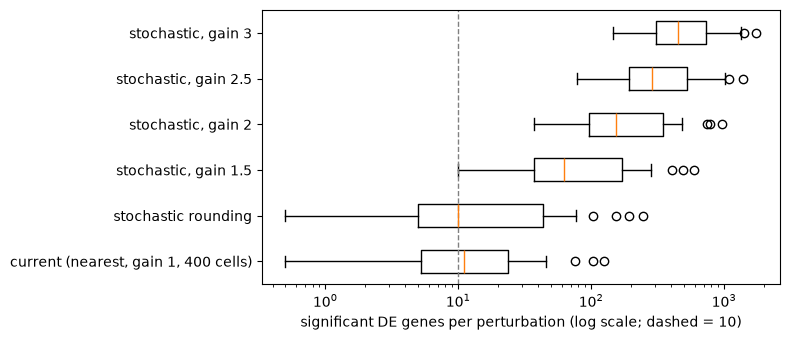

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.5))
order = list(SETTINGS)
ax.boxplot([calls.loc[calls.setting == s, "n_sig"].clip(lower=0.5) for s in order], orientation="horizontal")
ax.set_yticks(range(1, len(order) + 1), order)
ax.set_xscale("log")
ax.axvline(10, color="grey", ls="--", lw=1)
ax.set_xlabel("significant DE genes per perturbation (log scale; dashed = 10)")
plt.tight_layout()
plt.show()

## Proxy leaderboard

The cells above only count calls. `agree` checks calls against the model's own prediction, so it's always about 0.99.

This section scores the cells with the leaderboard's own formulas, using `proxy_score.py`:

- **Model:** fit without `HELD` (LOCO).
- **Proxy reference:** `HELD`'s *measured* effects applied to half of the context's control cells.
- **Comparison group:** the other half of the controls. It's the DE test's comparison group, and the model's cells are sampled from it.
- **Scaling:** every metric is scaled as (u − b)/(r − b), with:
  - b = the mean-vector baseline;
  - r = two 200-cell halves of the proxy reference, one scored against the other.

The held-out lines don't contain the VCC targets. So the panel is a random sample of `HELD`'s targets that were also perturbed in a training line, like the VCC panel.

Note on clamping: the brief clamps the *scaled* MSE to [0, 1] and floors the scaled NMAE at −6. MSE can never go below 0, so too high a gain is penalized through NMAE (and JAC), not MSE.

In [10]:
from proxy_score import proxy_leaderboard

HELD = "HepG2"                     # screen used as the proxy truth (RPE1, HepG2 or Jurkat)
N_PROXY = 40                       # panel size: ~25s per gain per 40 targets
GAINS = [1.25, 1.5, 2.0, 2.5, 3.0]

# LOCO fit: a separate Model, so the cells above keep the all-lines `model`
loco_train = [n for n in DATASETS if n != HELD]
loco = Model(gene_names, '../../data/embeddings/gene_string_embeddings.v0.3.h5', SlimConfig())
loco.config.K, loco.config.lambda_reg = K, LAM
loco.fit(*dp.build_Y(loco_train, genes="union"))

held = dp.load_dataset(HELD)
truth = pd.DataFrame((held.X - held.var["ctrl_mean"].to_numpy()) / np.log(2),   # measured log2FC
                     index=held.obs_names, columns=[dp.gene_index[g] for g in held.var_names])
loco.set_context(held.var["ctrl_mean"], dp.source_ctrls(loco_train), tau=0.05, mix=0.3,
                 panel=list(truth.index))
print(HELD, dict(zip(loco.source_names, loco.weights.round(2))))

# targets the training lines also perturbed (like the VCC panel), and that are genes in the panel
trained_on = set().union(*(dp.load_dataset(n).obs_names for n in loco_train))
candidates = [t for t in truth.index if t in trained_on and t in dp.gene_index]
proxy_targets = list(np.random.default_rng(SEED).choice(candidates, N_PROXY, replace=False))

  Fitted on 13823 perts, STRING coverage: 13315/13823
HepG2 {'K562': np.float64(0.37), 'RPE1': np.float64(0.37), 'Jurkat': np.float64(0.26)}


In [11]:
# scaled: 0 = mean-vector baseline, 1 = replicate (same as the leaderboard); raw: unscaled values.
# n_sig = median significant genes per perturbation; compare with "proxy reference" (n_real).
# Sanity check: raw baseline/replicate should sit near the brief's reference points
# (baseline fid ~0.51, jac ~0.03, nmae ~1.0; replicate fid ~0.8, jac ~0.4, nmae ~0.4).
t = time.time()
scaled, raw = proxy_leaderboard(loco, ctrl, truth, proxy_targets, GAINS, dp.gene_index,
                                kd=kd, alpha=ALPHA, seed=SEED)
print(f"{time.time() - t:.0f}s")
display(raw.round(3))
scaled.round(3)

scorer: 9929 DE-tested genes, 9200 comparison / 9200 pool cells (4s)
reference + replicate: 53s, median n_real 328
gain 1.25: 25s
gain 1.5: 25s
gain 2.0: 25s
gain 2.5: 25s
gain 3.0: 25s
184s


,pds,mse,fid,reach,jac,nmae,n_sig
baseline,0.500,0.872,0.534,0.013,0.043,0.914,9654.0
replicate,1.000,0.131,0.900,0.999,0.272,0.397,125.0
model gain 1.25,0.511,1.027,0.373,0.199,0.110,0.891,236.0
model gain 1.5,0.528,1.139,0.450,0.196,0.130,0.893,368.0
model gain 2.0,0.524,1.468,0.548,0.206,0.148,0.915,636.5
model gain 2.5,0.524,1.943,0.593,0.216,0.149,0.964,987.0
model gain 3.0,0.522,2.580,0.610,0.230,0.146,1.034,1277.5


,pds,mse,fid,reach,jac,nmae,overall,n_sig
baseline,0.000,-0.0,0.000,0.000,0.000,-0.000,0.000,9654.0
replicate,1.000,1.0,1.000,1.000,1.000,1.000,1.000,125.0
model gain 1.25,0.022,0.0,-0.442,0.188,0.293,0.045,0.018,236.0
model gain 1.5,0.056,0.0,-0.230,0.185,0.381,0.041,0.072,368.0
model gain 2.0,0.049,0.0,0.038,0.196,0.458,-0.002,0.123,636.5
model gain 2.5,0.049,0.0,0.161,0.206,0.465,-0.096,0.131,987.0
model gain 3.0,0.044,0.0,0.206,0.220,0.452,-0.231,0.115,1277.5
proxy reference,NaN,NaN,NaN,NaN,NaN,NaN,NaN,327.5
